# Анализ воронки продаж E-commerce (Ozon)

**Бизнес-контекст:** Крупный маркетплейс анализирует путь пользователя от просмотра товара до оформления заказа. Перед продуктовой командой стоит задача декомпозировать путь пользователя, найти узкие места (bottlenecks) и оценить, на каком этапе мы теряем наибольшую долю потенциальных покупателей.

**Источник данных:** Открытый датасет Ozon E-CUP 2025 (анонимизированные логи взаимодействий и заказов за период).
**Инструменты:** Python (Pandas, Matplotlib, Seaborn).

In [12]:
import glob
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

TRACKER_DIR = "../data/raw/ml_ozon_recsys_train_final_apparel_tracker_data"
ORDERS_DIR = "../data/raw/ml_ozon_recsys_train_final_apparel_orders_data"

tracker_files = glob.glob(os.path.join(TRACKER_DIR, "*.parquet"))
orders_files = glob.glob(os.path.join(ORDERS_DIR, "*.parquet"))

# Использование dtype_backend="pyarrow" для оптимизации памяти при больших объемах
df_orders = pd.concat(
    [pd.read_parquet(f, dtype_backend="pyarrow") for f in orders_files], 
    ignore_index=True
)
df_events = pd.concat(
    [pd.read_parquet(f, dtype_backend="pyarrow") for f in tracker_files], 
    ignore_index=True
)

print(f"Загружено событий: {df_events.shape[0]:,}")
print(f"Загружено заказов: {df_orders.shape[0]:,}")

Загружено событий: 40,636,008
Загружено заказов: 18,887,122


## 1. Первичный осмотр данных
Проверка структуры таблиц.

In [13]:
display(df_events.head(3))
display(df_orders.head(3))

,item_id,user_id,timestamp,action_type,action_widget,date
0,678602,4211601,2025-05-05 18:11:15,page_view,cart.cartSplit,2025-05-05
1,678602,4211601,2025-05-05 18:12:57,view_description,pdp.characteristics,2025-05-05
2,678602,4211601,2025-05-05 18:12:52,view_description,pdp.richContent,2025-05-05


,item_id,user_id,created_timestamp,last_status,last_status_timestamp,created_date
0,15535,3423970,2025-01-11 19:20:02.550000,delivered_orders,2025-01-16 10:53:03,2025-01-11
1,15535,1207601,2025-03-25 13:11:48.240000,canceled_orders,2025-03-29 08:32:43,2025-03-25
2,119241,2340021,2025-05-03 20:46:18.146000,canceled_orders,2025-05-12 17:10:27,2025-05-03


## 2. Распределение событий
Анализ частоты действий пользователей на платформе.

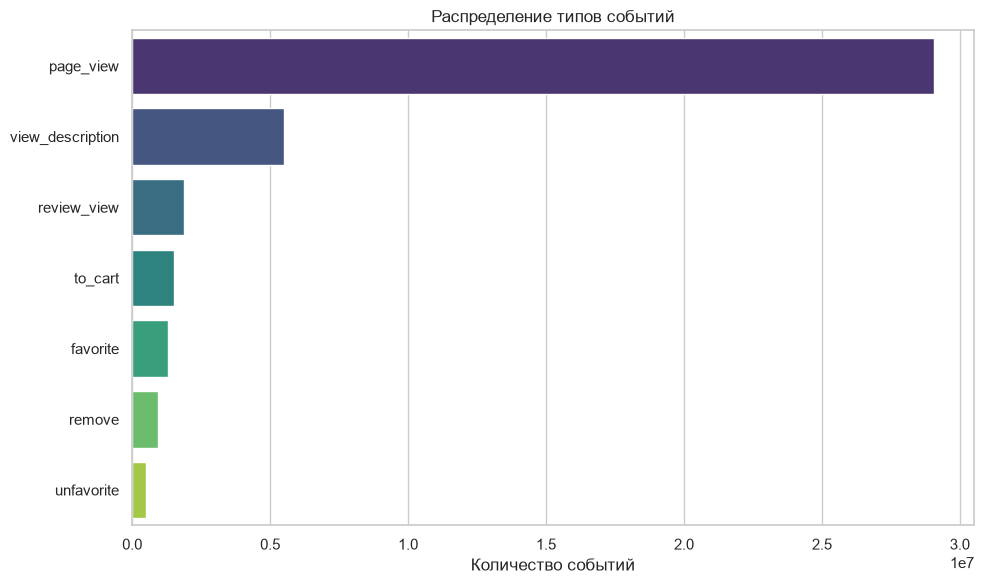

In [14]:
event_col = 'action_type'

events_counts = df_events[event_col].value_counts().reset_index()
events_counts.columns = [event_col, 'count']

fig, ax = plt.subplots()
sns.barplot(
    data=events_counts, 
    x='count', 
    y=event_col, 
    hue=event_col, 
    palette="viridis", 
    legend=False, 
    ax=ax
)
ax.set_title("Распределение типов событий")
ax.set_xlabel("Количество событий")
ax.set_ylabel("")
plt.tight_layout()

plt.savefig("../images/funnel/01_event_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Построение воронки продаж
Этап покупки рассчитывается по таблице заказов, так как в логах событий фиксируются только просмотры и действия в корзине.

In [15]:
user_col = 'user_id'

view_users = df_events[
    df_events[event_col].isin(['page_view', 'view_description'])
][user_col].nunique()

cart_users = df_events[
    df_events[event_col] == 'to_cart'
][user_col].nunique()

purchase_users = df_orders[user_col].nunique()

funnel_data = pd.DataFrame({
    'stage': ['View', 'To Cart', 'Purchase'],
    'users': [view_users, cart_users, purchase_users]
})

funnel_data['conversion_from_prev'] = (funnel_data['users'] / funnel_data['users'].shift(1) * 100).round(2)
funnel_data['conversion_from_start'] = (funnel_data['users'] / funnel_data['users'].iloc[0] * 100).round(2)

display(funnel_data)

,stage,users,conversion_from_prev,conversion_from_start
0,View,911347,NaN,100.00
1,To Cart,475006,52.12,52.12
2,Purchase,834137,175.61,91.53


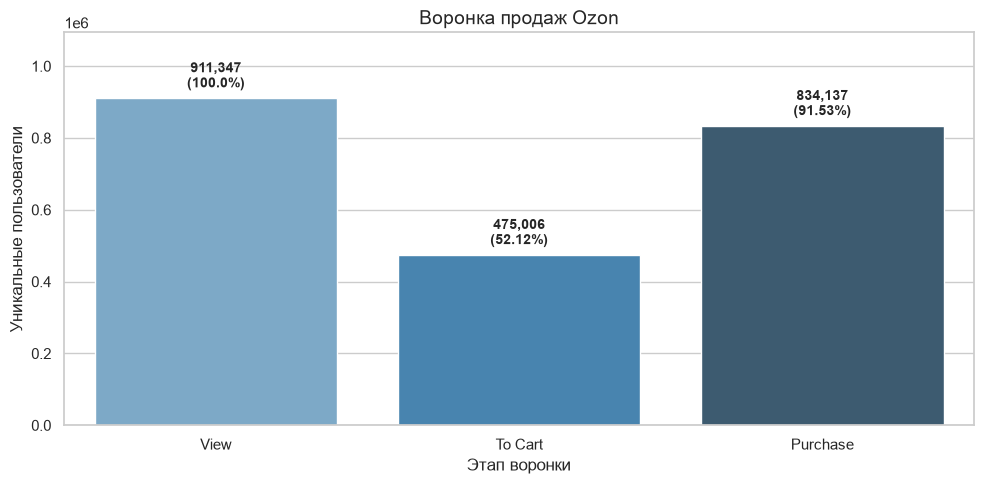

In [16]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(
    data=funnel_data, 
    x='stage', 
    y='users', 
    hue='stage', 
    palette='Blues_d', 
    legend=False, 
    ax=ax
)

for i, row in funnel_data.iterrows():
    ax.text(i, row['users'] + (funnel_data['users'].max() * 0.02), 
            f"{row['users']:,}\n({row['conversion_from_start']}%)", 
            ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_title("Воронка продаж Ozon", fontsize=14)
ax.set_xlabel("Этап воронки")
ax.set_ylabel("Уникальные пользователи")
ax.set_ylim(0, funnel_data['users'].max() * 1.2)
plt.tight_layout()

plt.savefig("../images/funnel/02_funnel_conversion.png", dpi=150, bbox_inches="tight")
plt.show()